# Leyenda: Deliverable 3, image captioning and the full workflow

## 1. Context

TouNum wants to caption its photographs automatically. The workflow has three steps: **classification** (photo or not, Deliverable 1), **denoising** (Deliverable 2) and **captioning** (this notebook). Deliverable 3 builds the captioning model and then chains the three steps in one reproducible pipeline.

### What this notebook will contain

1. The data: MS COCO 2014 captions and images, a seeded subset, the split by image.
2. Image preprocessing (a pre-trained CNN, InceptionV3, gives a feature grid for each image, computed once and stored on disk) and text preprocessing (tokenization, vocabulary, padding).
3. The captioning network (CNN features, attention, RNN decoder): architecture diagram, role of each layer, code.
4. Training curves (training and validation), and captioned test images.
5. The whole workflow (classification, denoising, captioning) as functions that can be called alone or chained.

*Work in progress: section 2 (the data) is written; the following ones come step by step.*

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from collections import Counter

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf

from src.config import COCO_DIR, SEED, SUBSET_SIZE
from src.coco import choose_subset, extract_images, load_captions, save_subset_ids

print("TensorFlow", tf.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
print(f"COCO_DIR={COCO_DIR} | SUBSET_SIZE={SUBSET_SIZE} | SEED={SEED}")

I0000 00:00:1792652054.488118    6137 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792652056.032457    6137 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | numpy 2.5.4 | matplotlib 3.11.2
COCO_DIR=data/coco | SUBSET_SIZE=2000 | SEED=42


## 2. The data: MS COCO 2014

**MS COCO** is a public dataset of photographs of everyday scenes. Each image comes with **several human-written captions** (5 or a little more). We use the 2014 version, `train2014` (the file names of 2014 and 2017 differ, we keep the 2014 ones).

### Reading the files

The data comes as two zip files, put in `data/coco/` (not versioned):

- `annotations_trainval2014.zip` (250 MB): among other files, `annotations/captions_train2014.json` (the captions);
- `train2014.zip` (13.5 GB): the 82,783 images, in a folder `train2014/`.

We **never extract the big zip**. The captions are read directly inside the small one, and only the images we choose are copied out of the big one.

### Captions grouped by image

In the JSON file, each caption is a separate entry `{image_id, caption}`. We group them by `image_id` to get, for each image, the list of its captions.

In [2]:
captions = load_captions()
n_captions = sum(len(c) for c in captions.values())
print(f"{len(captions):,} images with captions | {n_captions:,} captions")

per_image = Counter(len(c) for c in captions.values())
print("number of captions per image (number of images):", dict(sorted(per_image.items())))

82,783 images with captions | 414,113 captions
number of captions per image (number of images): {5: 82586, 6: 196, 7: 1}


### The subset

Training on 82,783 images would take far too long for our machines (some have a 2 GB GPU), so we use a **subset**. It is chosen once, with a seeded shuffle of all the image ids, and we keep the first `SUBSET_SIZE` (2,000 for the baseline). Everybody in the group gets the same images. With a shuffle, the subset of 2,000 is the beginning of a subset of 6,000 or 10,000: scaling up later only adds images, it never replaces the ones already used.

The ids are saved in `data/coco/subset_image_ids.json` so that teammates can check that they have the same list.

In [3]:
subset_ids = choose_subset(captions.keys(), SUBSET_SIZE)
save_subset_ids(subset_ids)
print(f"subset: {len(subset_ids)} images, {len(set(subset_ids))} different ids")
print("first ids:", subset_ids[:5])

# Checks. A second draw must give exactly the same list, and a bigger subset must start with this one.
assert choose_subset(captions.keys(), SUBSET_SIZE) == subset_ids
assert choose_subset(captions.keys(), 3 * SUBSET_SIZE)[:SUBSET_SIZE] == subset_ids
print("same list on a second draw: True | the subset of", 3 * SUBSET_SIZE, "starts with this subset: True")

fewest = min(len(captions[i]) for i in subset_ids)
print(f"every image of the subset has at least {fewest} captions (smallest number in the subset)")

subset: 2000 images, 2000 different ids
first ids: [29586, 356064, 372163, 400729, 333841]
same list on a second draw: True | the subset of 6000 starts with this subset: True
every image of the subset has at least 5 captions (smallest number in the subset)


### Copying the images of the subset

Only the 2,000 chosen images are copied from the zip to `data/coco/train2014/` (about 300 MB). If the cell is run again, the images already copied are skipped. Then we check that **every file is there and can be decoded**.

In [4]:
image_paths = extract_images(subset_ids)

missing = [p for p in image_paths if not os.path.exists(p)]
print(f"{len(image_paths)} paths | missing files: {len(missing)}")

# Decoding every image: a damaged file would break the feature extraction later, better to find it now.
heights, widths, bad = [], [], []
for path in image_paths:
    try:
        # channels=3: some COCO images are grayscale, they are converted to RGB.
        image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        heights.append(image.shape[0]); widths.append(image.shape[1])
    except tf.errors.InvalidArgumentError:
        bad.append(path)
print(f"images that cannot be decoded: {len(bad)}")
print(f"original sizes: height {min(heights)}-{max(heights)}, width {min(widths)}-{max(widths)} (median {int(np.median(heights))} x {int(np.median(widths))})")

2000 paths | missing files: 0
images that cannot be decoded: 0
original sizes: height 135-640, width 172-640 (median 480 x 640)


### One example

An image of the subset with all its captions. The captions are written by different people: they describe the same scene with different words, and that is what the model will have to learn from.

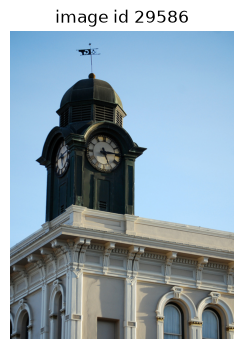

- A white building with a dark clock tower.
- two white and black clocks a black clock tower and white building
- Large building with clock tower on sunny day.
- A clock tower ring above an ornate building in the foreground.
- A clock that is at the top of a building.


In [5]:
example_id, example_path = subset_ids[0], image_paths[0]
plt.figure(figsize=(5, 4))
plt.imshow(plt.imread(example_path)); plt.axis("off"); plt.title(f"image id {example_id}")
plt.show()
for caption in captions[example_id]:
    print("-", caption)